# Week 4 - Univariate Analysis, part 2

# 1. Lesson - None

# 2. Weekly graph question

Below are a histogram and boxplot representation of the same data. A pharmacy is keeping a record of the prices of the drugs that it sells, and an administrator wants to know how much the more expensive drugs tend to cost, in the context of the other prices.

Please write a short explanation of the pros and cons of these two representations. Which would you choose? How would you modify the formatting, if at all, to make it more visually interesting, clear, or informative?

In [1]:
import numpy as np
import pandas as pd

np.random.seed(0)
num_data = 100
data = np.exp(np.random.uniform(size = num_data) * 4)
df = pd.DataFrame(data.T, columns = ["data"])

The 75th percentile is: data    15.457656
Name: 0.75, dtype: float64


<Axes: ylabel='Frequency'>

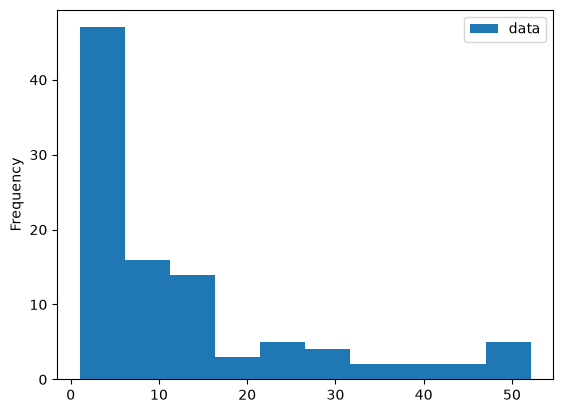

In [2]:
print("The 75th percentile is:", df.quantile(q = 0.75))
df.plot.hist()

<Axes: >

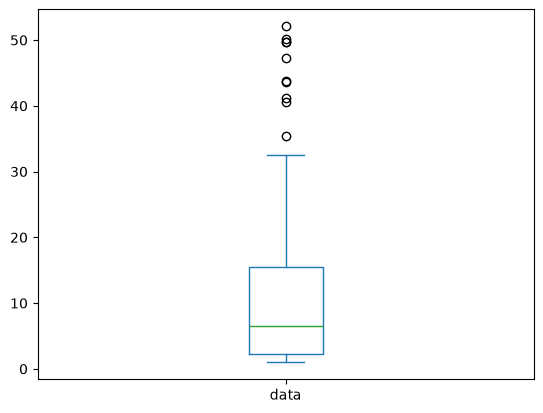

In [3]:
df.plot.box()

**Histogram:** It shows the shape clearly. Most drugs are cheap and only a few are expensive. But the expensive drugs, which are what the administrator actually cares about, are tiny bars that are easy to miss. There's also no title or axis label.

**Boxplot:** It shows the expensive drugs directly. The top of the box is the 75th percentile (~$15), and the dots above the whisker are the most expensive drugs, up to about $52. It does hide how bunched up the cheap drugs are and it also has no title or labels.

**My choice:** The boxplot, since it answers the question. I'd add a title to this and label the axis "Price ($)."

# 3. Homework - working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Draw histograms and histogram variants for each feature or column.  (Swarm plot, kde plot, violin plot).

- Draw grouped histograms.  For instance, if you have tree heights for both maple and oak trees, you could draw histograms for both.

- Draw a bar plot to indicate total counts of each categorical variable in a given column.

- Find means, medians, and modes.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If they are not useable, find some new data!

- What is the overall shape of the distribution?  Is it normal, skewed, bimodal, uniform, etc.?

- Are there any outliers present?  (Data points that are far from the others.)

- If there are multiple related histograms, how does the distribution change across different groups?

- What are the minimum and maximum values represented in each histogram?

- How do bin sizes affect the histogram?  Does changing the bin width reveal different patterns in the data?

- Does the distribution appear normal, or does it have a different distribution?

**Dataset:** Diabetes 130-US Hospitals (1999–2008), same as Week 2

**File used:** diabetic_data.csv

Same cleaning steps as Week 2.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('diabetic_data.csv')
id_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)
df = df.replace('?', np.nan)
df = df.drop(columns=['weight', 'payer_code', 'medical_specialty'])
df['race'] = df['race'].fillna('Unknown')
df = df.dropna(subset=['diag_1', 'diag_2', 'diag_3'])
df['max_glu_serum'] = df['max_glu_serum'].fillna('Not tested')
df['A1Cresult'] = df['A1Cresult'].fillna('Not tested')
df = df[df['gender'] != 'Unknown/Invalid']
df = df[~df['discharge_disposition_id'].isin(['11', '19', '20', '21'])]
print("Rows after cleaning:", len(df))

Rows after cleaning: 98591


### Histograms for each numeric column

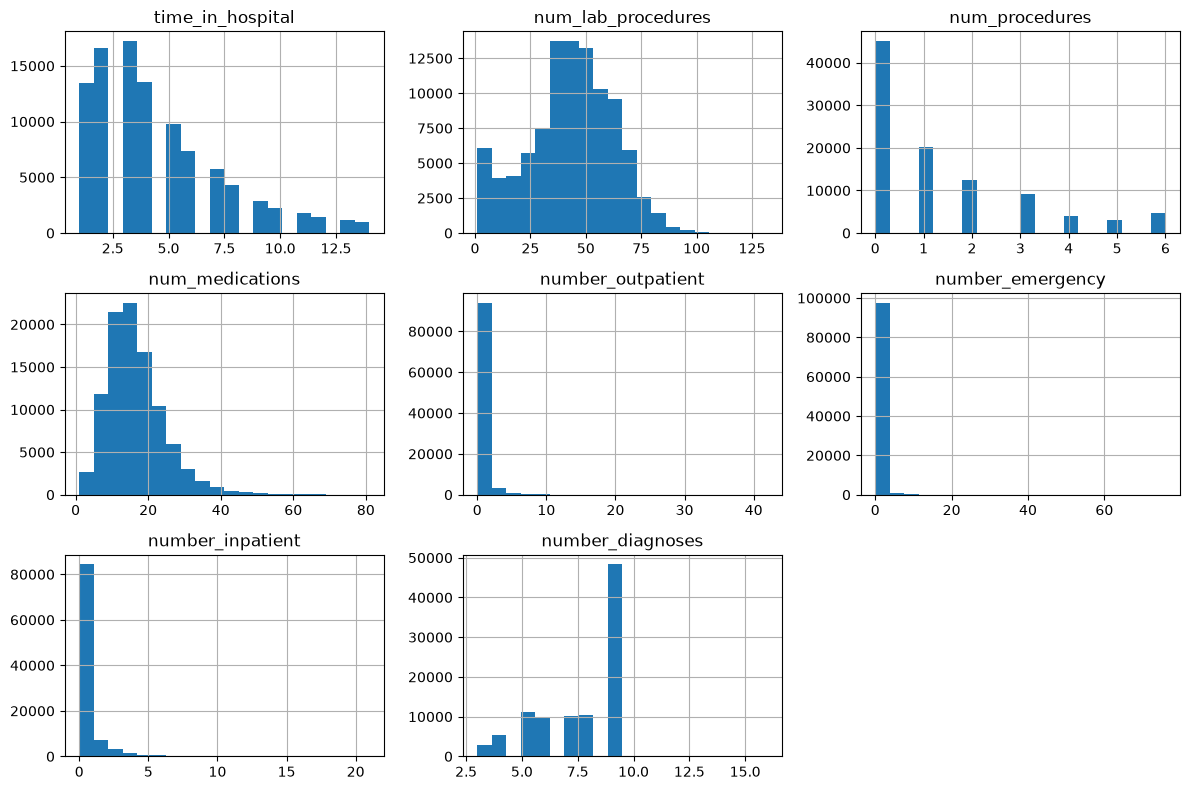

In [5]:
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
df[num_cols].hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

**NOtes**

- **num_lab_procedures** is the only one that looks close to normal, but it has a big spike at 1.
- **time_in_hospital, num_medications, num_procedures** are skewed right. Most stays are short and a few are long.
- **number_outpatient, number_emergency, number_inpatient** are mostly 0 (83%, 89% and 66% of visits), with a long tail of a few patients who have a lot of visits.
- **number_diagnoses** stops at 9 for almost everyone, with only a handful above that. It looks like the system only recorded up to 9 for most of the data.

### # of bins adj.

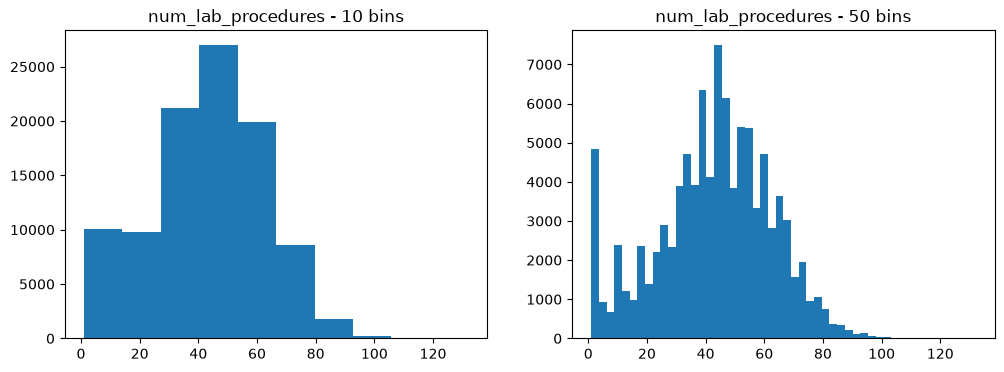

Visits with exactly 1 lab procedure: 3126


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.hist(df['num_lab_procedures'], bins=10)
ax1.set_title('num_lab_procedures - 10 bins')
ax2.hist(df['num_lab_procedures'], bins=50)
ax2.set_title('num_lab_procedures - 50 bins')
plt.show()

print("Visits with exactly 1 lab procedure:", (df['num_lab_procedures'] == 1).sum())

With 10 bins it looks like a normal bell curve. With 50 bins you can see a spike at 1 lab procedure (about 3,100 visits). That's actually the mode. So the smaller bins showed something the bigger bins hid.

### Histogram variants

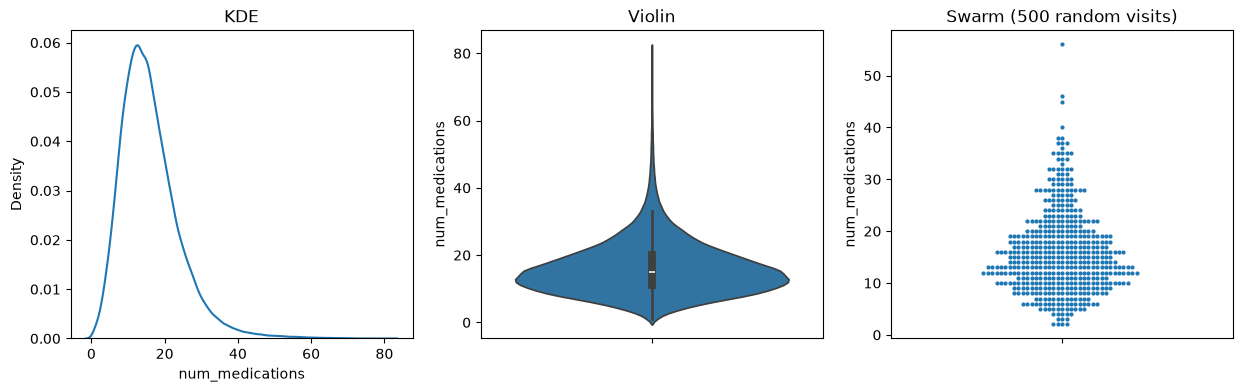

In [7]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))
sns.kdeplot(df['num_medications'], ax=ax1)
ax1.set_title('KDE')
sns.violinplot(y=df['num_medications'], ax=ax2)
ax2.set_title('Violin')
sample = df.sample(500, random_state=0)
sns.swarmplot(y=sample['num_medications'], ax=ax3, size=3)
ax3.set_title('Swarm (500 random visits)')
plt.show()

All three show num_medications bunched around 10–20 with a long tail to the right (max is 81). The swarm plot had to use a sample of 500 because plotting all ~98k points would take forever. The violin plot is the most useful here since it shows the shape and the box plot at the same time.

### Grouped histograms by readmission

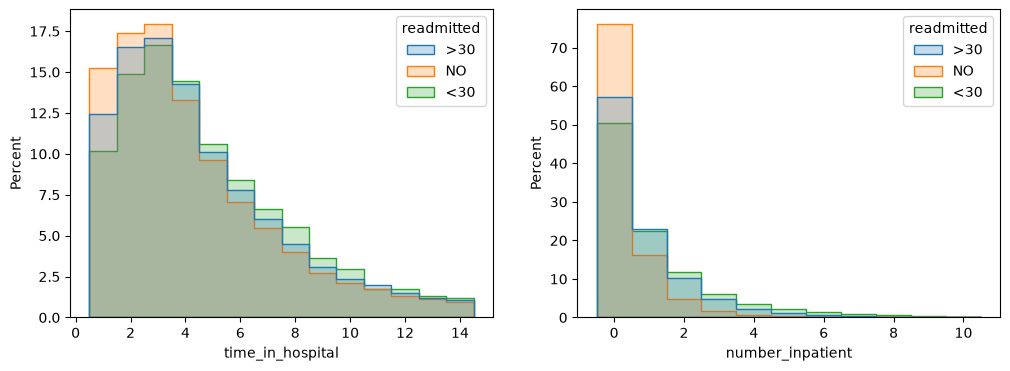

            time_in_hospital  number_inpatient  number_emergency
readmitted                                                      
<30                     4.78              1.22              0.36
>30                     4.51              0.84              0.28
NO                      4.27              0.37              0.11


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='time_in_hospital', hue='readmitted', stat='percent',
             common_norm=False, discrete=True, element='step', ax=ax1)
sns.histplot(data=df[df['number_inpatient'] <= 10], x='number_inpatient', hue='readmitted', stat='percent',
             common_norm=False, discrete=True, element='step', ax=ax2)
plt.show()

print(df.groupby('readmitted')[['time_in_hospital', 'number_inpatient', 'number_emergency']].mean().round(2))

I used percent instead of counts because the NO group is much bigger than the <30 group. time_in_hospital looks about the same for all three groups (the <30 group stays slightly longer, 4.8 vs 4.3 days). number_inpatient is where they really split: the NO group is mostly at 0, while the <30 group has more patients with past inpatient visits.

In [9]:
pd.crosstab(df['number_inpatient'].clip(upper=4), df['readmitted'], normalize='index').round(2)

readmitted,<30,>30,NO
number_inpatient,,,
0,0.09,0.31,0.61
1,0.13,0.43,0.44
2,0.18,0.49,0.33
3,0.21,0.51,0.28
4,0.31,0.49,0.19


Patients with 0 prior inpatient visits are readmitted within 30 days 9% of the time. Patients with 4+ prior visits are readmitted 31% of the time. This lines up with previous exploaration from week 2. 

### Bar plots of categorical columns

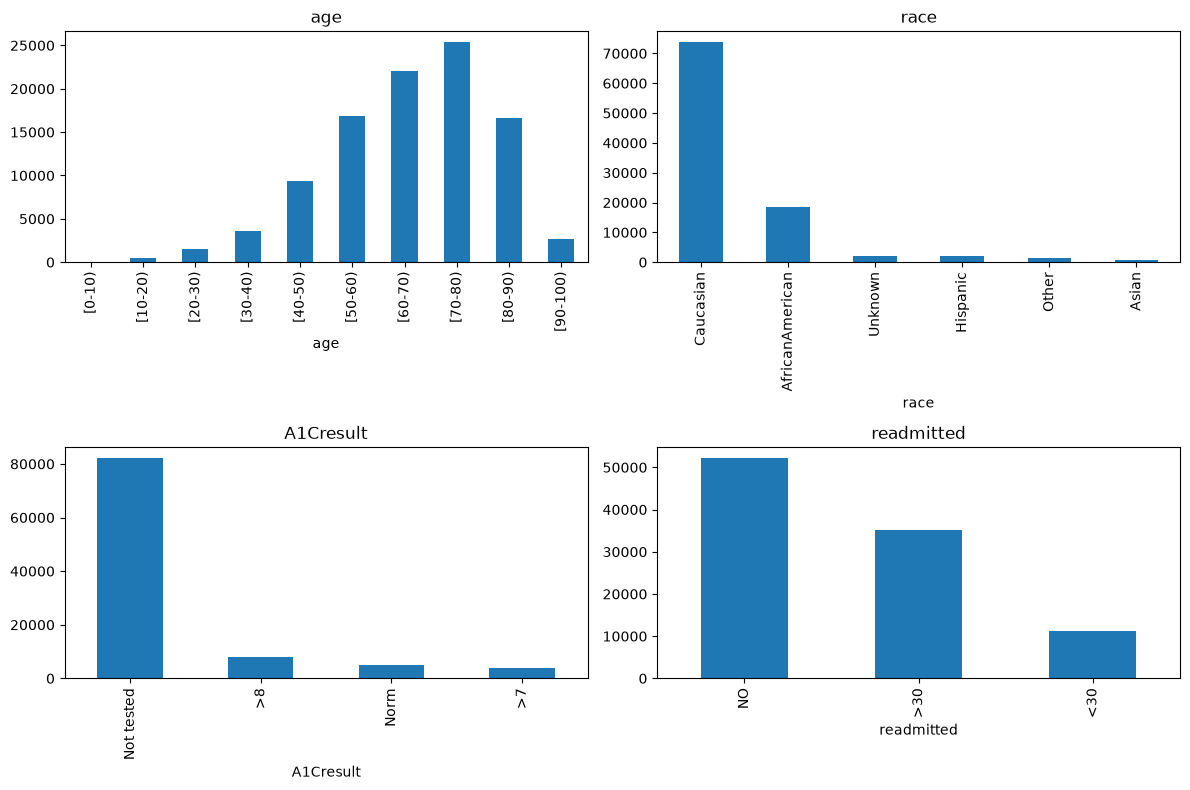

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
df['age'].value_counts().sort_index().plot.bar(ax=axes[0, 0], title='age')
df['race'].value_counts().plot.bar(ax=axes[0, 1], title='race')
df['A1Cresult'].value_counts().plot.bar(ax=axes[1, 0], title='A1Cresult')
df['readmitted'].value_counts().plot.bar(ax=axes[1, 1], title='readmitted')
plt.tight_layout()
plt.show()

- **age:** mostly older patients. 50–90 is the bulk, and [70-80) is the biggest group.
- **race:** about 75% Caucasian and 19% African American, so the other groups are small.
- **A1Cresult:** about 83% were never tested, which is surprising for diabetic patients.
- **readmitted:** same imbalance as Week 2: 53% NO, 36% >30, 11% <30.

### Mean, median, mode, min, max

In [11]:
summary = pd.DataFrame({
    'mean': df[num_cols].mean().round(1),
    'median': df[num_cols].median(),
    'mode': df[num_cols].mode().iloc[0],
    'min': df[num_cols].min(),
    'max': df[num_cols].max()
})
summary

,mean,median,mode,min,max
time_in_hospital,4.4,4.0,3,1,14
num_lab_procedures,43.0,44.0,1,1,132
num_procedures,1.3,1.0,0,0,6
num_medications,16.1,15.0,13,1,81
number_outpatient,0.4,0.0,0,0,42
number_emergency,0.2,0.0,0,0,76
number_inpatient,0.6,0.0,0,0,21
number_diagnoses,7.5,8.0,9,3,16


### Conclusions

- **Are the data what I expected / usable?** 
Yes. Mostly older patients, short hospital stays, and most people have few prior visits. That makes sense for hospital data. The data is usable.
- **Shape:** 
num_lab_procedures is close to normal (except the spike at 1). time_in_hospital, num_medications and num_procedures are skewed right. The three visit count columns are heavily skewed with most values at 0. number_diagnoses is skewed left and capped at 9.
- **Outliers:** 
number_emergency (up to 76), number_outpatient (up to 42) and number_inpatient (up to 21) have a few patients far from the rest. num_medications goes up to 81.
- **Across groups:** 
time_in_hospital barely changes between readmission groups, but number_inpatient changes a lot. More prior inpatient visits means a higher chance of readmission within 30 days.
- **Min and max:** 
see the summary table above.
- **Bin sizes:** 
10 bins made num_lab_procedures look normal. 50 bins showed the spike at 1.
- **Normal?** 
Only num_lab_procedures is roughly normal. Everything else is skewed.

# 4. Storytelling With Data graph

Reproduce any graph of your choice in p. 52-68 of the Storytelling With Data book as best you can.  (The second half of chapter two).  You do not have to get the exact data values right, just the overall look and feel.

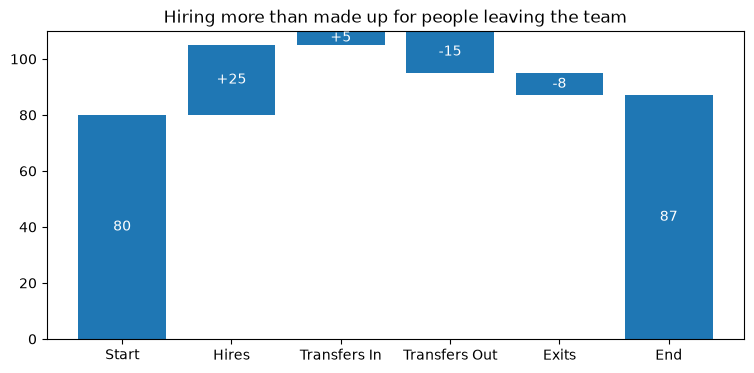

In [12]:
labels = ['Start', 'Hires', 'Transfers In', 'Transfers Out', 'Exits', 'End']
heights = [80, 25, 5, -15, -8, 87]
bottoms = [0, 80, 105, 110, 95, 0]
text = ['80', '+25', '+5', '-15', '-8', '87']

plt.figure(figsize=(9, 4))
bars = plt.bar(labels, heights, bottom=bottoms)
plt.bar_label(bars, labels=text, label_type='center', color='white')
plt.title('Hiring more than made up for people leaving the team')
plt.show()

My rough version of the waterfall chart (Figure 2.17) with my own numbers. Each bar starts where the last one ended, which I did with `bottom=` in `plt.bar`.